In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nelgiriyewithana/emotions")

print("Path to dataset files:", path)

100%|██████████| 15.7M/15.7M [00:00<00:00, 110MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/nelgiriyewithana/emotions/versions/1


In [ ]:
import os

# List the contents of the downloaded directory
print(os.listdir(path))

['text.csv']


In [ ]:
import pandas as pd
df = pd.read_csv(f"{path}/text.csv")
df.head(10)

,Unnamed: 0,text,label
0,0,i just feel really helpless and heavy hearted,4
1,1,ive enjoyed being able to slouch about relax a...,0
2,2,i gave up my internship with the dmrg and am f...,4
3,3,i dont know i feel so lost,0
4,4,i am a kindergarten teacher and i am thoroughl...,4
5,5,i was beginning to feel quite disheartened,0
6,6,i would think that whomever would be lucky eno...,2
7,7,i fear that they won t ever feel that deliciou...,1
8,8,im forever taking some time out to have a lie ...,5
9,9,i can still lose the weight without feeling de...,0


In [ ]:
df['label'].value_counts()

,count
label,
1,141067
0,121187
3,57317
4,47712
2,34554
5,14972


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [ ]:
#Six categories: sadness (0), joy (1), love (2), anger (3), fear (4), and surprise (5).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.25, random_state=42, stratify=df['label']
)
vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.91      0.94     30297
           1       0.97      0.88      0.92     35267
           2       0.72      0.95      0.81      8639
           3       0.87      0.92      0.90     14329
           4       0.85      0.85      0.85     11928
           5       0.65      0.92      0.76      3743

    accuracy                           0.90    104203
   macro avg       0.84      0.90      0.86    104203
weighted avg       0.91      0.90      0.90    104203



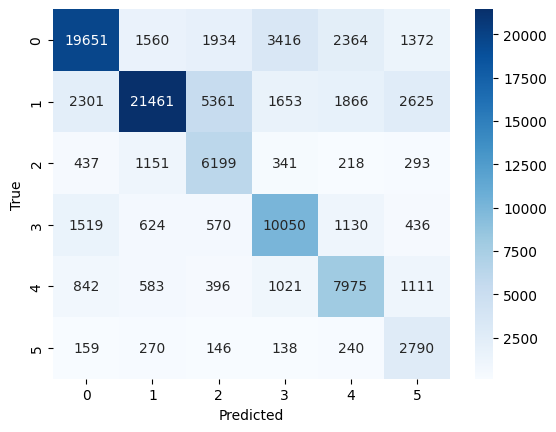

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [ ]:
tf_idf = TfidfVectorizer(ngram_range=(1,2), max_features=20000, min_df = 2)

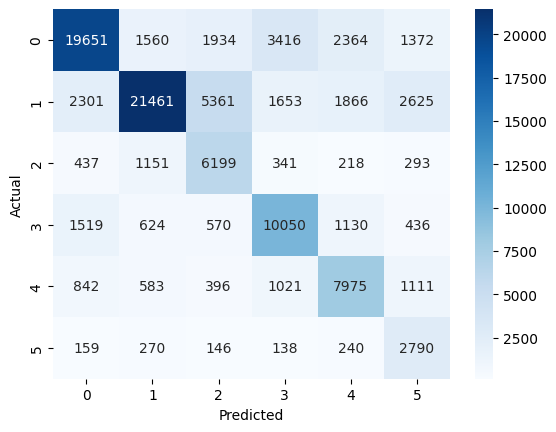

In [ ]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,          # ignore words in fewer than 3 documents
    max_df=0.9,        # ignore words in more than 90% of documents
    sublinear_tf=True  # dampens effect of very frequent words
)

In [ ]:
new_texts = [
    "I can't stop smiling, today turned out better than I ever imagined.",   # joy
    "Ever since she left, the house just feels so empty and quiet.",         # sadness
    "He's been the only person who truly gets me, and I cherish that.",     # love
    "I slammed the door so hard my hand still hurts from the anger.",       # anger
    "My heart was racing the entire time we walked through the dark alley.", # fear
    "I never expected to see him standing there — it caught me completely off guard.", # surprise
    "Waking up to sunlight and birds singing just makes everything feel okay.",  # joy
    "There's a heaviness in my chest that won't seem to lift these days.",  # sadness
]
#Six categories: sadness (0), joy (1), love (2), anger (3), fear (4), and surprise (5).
new_texts_vec = vectorizer.transform(new_texts)
new_pred = model.predict(new_texts_vec)
print(new_pred)

[1 0 3 3 4 4 1 0]


In [ ]:
print(df[df['label'] == 2].sample(10)['text'])   # love examples
print('hi')
print(df[df['label'] == 5].sample(10)['text'])   # surprise examples

55976     i love you because you make me feel loved safe...
201935    i am feeling sympathetic and attached to an an...
315175    i cant feel a thing but i also cant feel how h...
154333    i would call you a retard right now but you pr...
39516       im definitely feeling blessed this time of year
352573    i have a doozy of a disagreement both of us fe...
5826      i trust exo more than my family and i feel lov...
219836    i kissed and savored the feel of her long neck...
290297    i feel kind of naughty because i have to take ...
163474    i feel like it is a delicate situation that co...
Name: text, dtype: object
hi
107299    i feel amazed to realize the world exists outs...
47284     i must admit i feel a bit like a rockstar whic...
101730                    i just feel so dazed and confused
241442    i remember walking out of the second film for ...
286982    i didn t mention and you are left feeling curious
258388    im feeling a little quilty so dont be surprise...
405072    i

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.25, random_state=42, stratify=df['label']
)
#X_train = X_train[:2000]
#X_test = X_test[:2000]
#y_train = y_train[:2000]
#y_test = y_test[:2000]
X_train_vec = embedder.encode(X_train.tolist(), show_progress_bar=True)
X_test_vec = embedder.encode(X_test.tolist(), show_progress_bar=True)

Batches:   0%|          | 0/9769 [00:00<?, ?it/s]

Batches:   0%|          | 0/3257 [00:00<?, ?it/s]

In [ ]:
print(X_train_vec.shape)

(312606, 384)


In [ ]:
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.65      0.71     30297
           1       0.84      0.61      0.70     35267
           2       0.42      0.72      0.53      8639
           3       0.60      0.70      0.65     14329
           4       0.58      0.67      0.62     11928
           5       0.32      0.75      0.45      3743

    accuracy                           0.65    104203
   macro avg       0.59      0.68      0.61    104203
weighted avg       0.71      0.65      0.67    104203



In [ ]:
labelencoder = LabelEncoder()
train_df = pd.read_csv(f"{path}/text.csv")
train_df['label'] = labelencoder.fit_transform(train_df['text'])
test_df = pd.read_csv(f"{path}/text.csv")
test_df['label'] = labelencoder.fit_transform(test_df['text'])
val_df = pd.read_csv(f"{path}/text.csv")
val_df['label'] = labelencoder.fit_transform(val_df['text'])

100%|██████████| 15.7M/15.7M [00:01<00:00, 16.1MB/s]

Extracting files...


Data shape: (416809, 3)
label
1    141067
0    121187
3     57317
4     47712
2     34554
5     14972
Name: count, dtype: int64
Train size: (333447,) | Test size: (83362,)
Unigram feature count: 20000
Bigram feature count: 20000
Feature counts differ? False

===== Bigram + class_weight='balanced' =====
              precision    recall  f1-score   support

     sadness       0.97      0.92      0.95     24238
         joy       0.98      0.88      0.93     28214
        love       0.73      0.96      0.83      6911
       anger       0.88      0.94      0.91     11463
        fear       0.86      0.85      0.86      9542
    surprise       0.67      0.93      0.78      2994

    accuracy                           0.91     83362
   macro avg       0.85      0.91      0.87     83362
weighted avg       0.92      0.91      0.91     83362



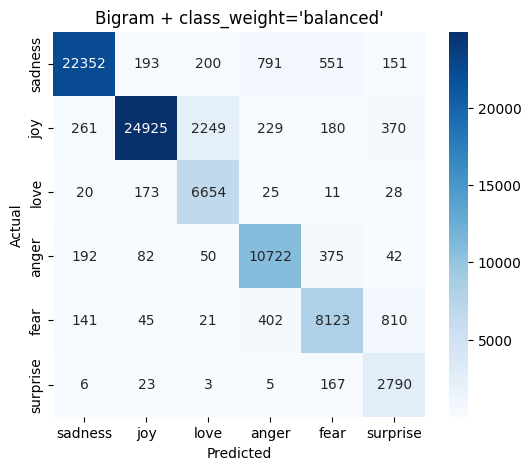


===== Bigram + class_weight=None =====
              precision    recall  f1-score   support

     sadness       0.94      0.95      0.95     24238
         joy       0.92      0.93      0.93     28214
        love       0.79      0.76      0.78      6911
       anger       0.90      0.90      0.90     11463
        fear       0.85      0.84      0.85      9542
    surprise       0.75      0.69      0.72      2994

    accuracy                           0.90     83362
   macro avg       0.86      0.85      0.85     83362
weighted avg       0.90      0.90      0.90     83362



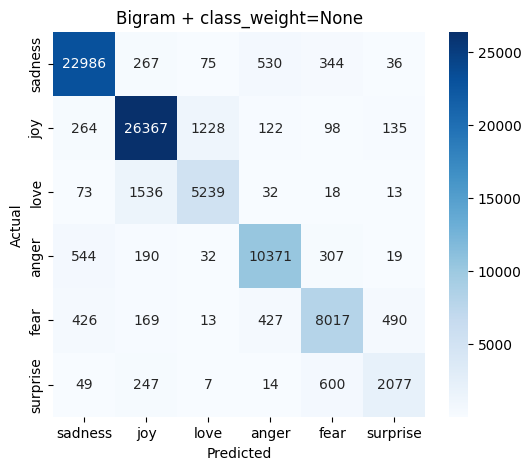


===== Bigram + custom weights =====
              precision    recall  f1-score   support

     sadness       0.95      0.94      0.95     24238
         joy       0.96      0.90      0.93     28214
        love       0.73      0.94      0.82      6911
       anger       0.91      0.90      0.90     11463
        fear       0.91      0.80      0.85      9542
    surprise       0.68      0.95      0.79      2994

    accuracy                           0.91     83362
   macro avg       0.85      0.90      0.87     83362
weighted avg       0.91      0.91      0.91     83362



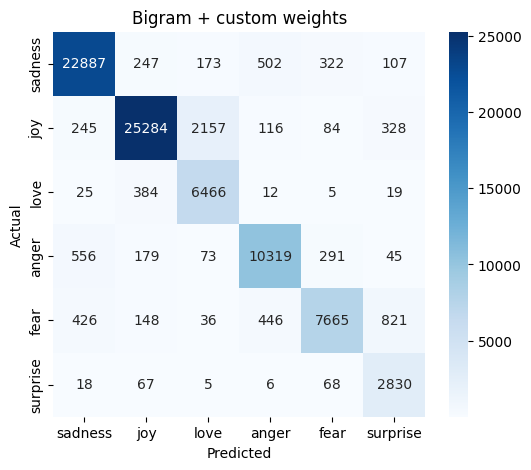


Are 'balanced' and 'none' predictions identical? False
Are 'balanced' and 'custom' predictions identical? False


In [ ]:
import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------
path = kagglehub.dataset_download("nelgiriyewithana/emotions")
df = pd.read_csv(f"{path}/text.csv")  # adjust filename if yours differs

print("Data shape:", df.shape)
print(df['label'].value_counts())

labels = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

# ---------------------------------------------------------
# 2. Train/test split
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)
print("Train size:", X_train.shape, "| Test size:", X_test.shape)

# ---------------------------------------------------------
# 3. TF-IDF — unigram (old) vs bigram (new) — kept as SEPARATE variables
#    so neither overwrites the other by accident
# ---------------------------------------------------------
tfidf_unigram = TfidfVectorizer(max_features=20000)
X_train_uni = tfidf_unigram.fit_transform(X_train)
X_test_uni = tfidf_unigram.transform(X_test)
print("Unigram feature count:", len(tfidf_unigram.get_feature_names_out()))

tfidf_bigram = TfidfVectorizer(
    ngram_range=(1, 2), max_features=20000, min_df=3, max_df=0.9, sublinear_tf=True
)
X_train_bi = tfidf_bigram.fit_transform(X_train)
X_test_bi = tfidf_bigram.transform(X_test)
print("Bigram feature count:", len(tfidf_bigram.get_feature_names_out()))
print("Feature counts differ?", len(tfidf_unigram.get_feature_names_out()) != len(tfidf_bigram.get_feature_names_out()))

# ---------------------------------------------------------
# 4. Three class-weight variants, all trained on the SAME bigram features,
#    so weighting is the only thing that changes between them
# ---------------------------------------------------------
def evaluate(clf, X_tr, y_tr, X_te, y_te, name):
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)
    print(f"\n===== {name} =====")
    print(classification_report(y_te, y_pred, target_names=labels))
    cm = confusion_matrix(y_te, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    return clf, y_pred

clf_balanced, pred_balanced = evaluate(
    LogisticRegression(class_weight='balanced', max_iter=1000),
    X_train_bi, y_train, X_test_bi, y_test, "Bigram + class_weight='balanced'"
)

clf_none, pred_none = evaluate(
    LogisticRegression(class_weight=None, max_iter=1000),
    X_train_bi, y_train, X_test_bi, y_test, "Bigram + class_weight=None"
)

clf_custom, pred_custom = evaluate(
    LogisticRegression(class_weight={0: 1, 1: 1, 2: 3, 3: 1, 4: 1, 5: 4}, max_iter=1000),
    X_train_bi, y_train, X_test_bi, y_test, "Bigram + custom weights"
)

# ---------------------------------------------------------
print("\nAre 'balanced' and 'none' predictions identical?", (pred_balanced == pred_none).all())
print("Are 'balanced' and 'custom' predictions identical?", (pred_balanced == pred_custom).all())

In [ ]:
samples = [
    "I can't believe you did this, I'm so proud of you",  # mixed signal
    "wow just wow",                                        # ambiguous surprise/sarcasm
    "I'm fine.",                                            # short, deadpan
]

X_samples = tfidf_bigram.transform(samples)
preds = clf_balanced.predict(X_samples)
probs = clf_balanced.predict_proba(X_samples)

for text, pred, prob in zip(samples, preds, probs):
    print(text, "->", labels[pred], "| confidence:", round(prob.max(), 2))

I can't believe you did this, I'm so proud of you -> joy | confidence: 0.8
wow just wow -> sadness | confidence: 0.26
I'm fine. -> joy | confidence: 1.0


Using Colab cache for faster access to the 'emotions' dataset.
Train size: (333447,) | Test size: (83362,)
Unigram feature count: 20000
Bigram feature count: 20000
Feature counts differ? False

===== Bigram + Linear SVC =====
              precision    recall  f1-score   support

     sadness       0.96      0.94      0.95     24238
         joy       0.96      0.90      0.93     28214
        love       0.73      0.88      0.80      6911
       anger       0.89      0.92      0.90     11463
        fear       0.84      0.84      0.84      9542
    surprise       0.67      0.78      0.72      2994

    accuracy                           0.90     83362
   macro avg       0.84      0.88      0.86     83362
weighted avg       0.91      0.90      0.90     83362



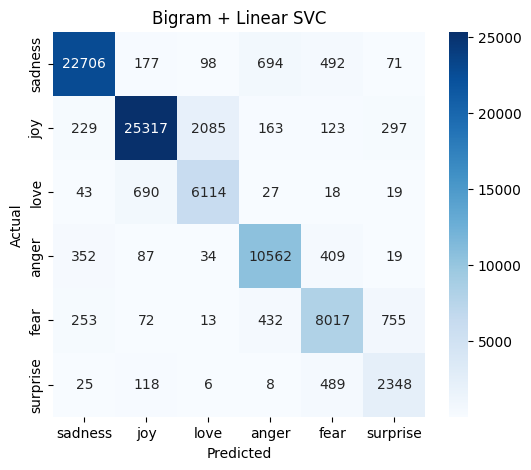

In [ ]:
import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier


# 1. Load data

path = kagglehub.dataset_download("nelgiriyewithana/emotions")
df = pd.read_csv(f"{path}/text.csv")  # adjust filename if yours differs

labels = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


# 2. Train/test split

X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)
print("Train size:", X_train.shape, "| Test size:", X_test.shape)


# 3. TF-IDF — unigram (old) vs bigram (new) — kept as SEPARATE variables
#    so neither overwrites the other by accident

tfidf_unigram = TfidfVectorizer(max_features=20000)
X_train_uni = tfidf_unigram.fit_transform(X_train)
X_test_uni = tfidf_unigram.transform(X_test)
print("Unigram feature count:", len(tfidf_unigram.get_feature_names_out()))

tfidf_bigram = TfidfVectorizer(
    ngram_range=(1, 2), max_features=20000, min_df=3, max_df=0.9, sublinear_tf=True
)
X_train_bi = tfidf_bigram.fit_transform(X_train)
X_test_bi = tfidf_bigram.transform(X_test)
print("Bigram feature count:", len(tfidf_bigram.get_feature_names_out()))
print("Feature counts differ?", len(tfidf_unigram.get_feature_names_out()) != len(tfidf_bigram.get_feature_names_out()))


# 4. Three class-weight variants, all trained on the SAME bigram features,
#    so weighting is the only thing that changes between them

def evaluate(clf, X_tr, y_tr, X_te, y_te, name):
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)
    print(f"\n===== {name} =====")
    print(classification_report(y_te, y_pred, target_names=labels))
    cm = confusion_matrix(y_te, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    return clf, y_pred

csvm = LinearSVC(class_weight='balanced', C=1.0, max_iter=5000)
csvm, pred_svm = evaluate(csvm, X_train_bi, y_train, X_test_bi, y_test, "Bigram + Linear SVC")

c_rf = RandomForestClassifier(
    n_estimators=200, class_weight='balanced', max_depth = None, n_jobs=1, random_state=29
)

c_rf, pred_rf = evaluate(c_rf, X_train_bi, y_train, X_test_bi, y_test, "Bigram + RandomForest")


Using Colab cache for faster access to the 'emotions' dataset.
Train size: (333447,) | Test size: (83362,)
Bigram feature count: 10000
Training model...

===== Bigram + RandomForest =====
              precision    recall  f1-score   support

     sadness       0.91      0.70      0.79     24238
         joy       0.77      0.84      0.80     28214
        love       0.68      0.95      0.80      6911
       anger       0.88      0.85      0.86     11463
        fear       0.86      0.79      0.82      9542
    surprise       0.64      0.98      0.77      2994

    accuracy                           0.81     83362
   macro avg       0.79      0.85      0.81     83362
weighted avg       0.82      0.81      0.81     83362



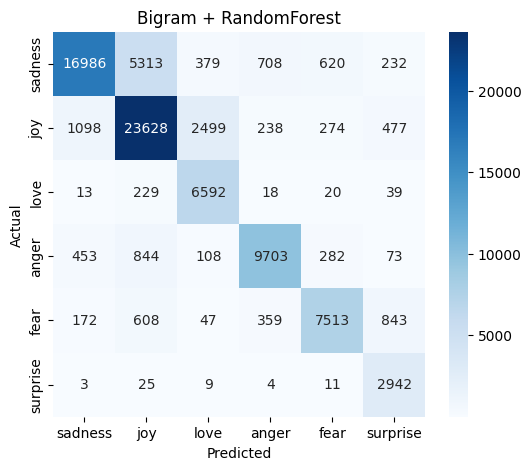

In [ ]:
import kagglehub
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load data
path = kagglehub.dataset_download("nelgiriyewithana/emotions")
df = pd.read_csv(f"{path}/text.csv")

labels = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)
print("Train size:", X_train.shape, "| Test size:", X_test.shape)

# 3. TF-IDF Bigram Vectorization
tfidf_bigram = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10000,   # Reduced max_features for faster evaluation
    min_df=3,
    max_df=0.9,
    sublinear_tf=True
)

X_train_bi = tfidf_bigram.fit_transform(X_train)
X_test_bi = tfidf_bigram.transform(X_test)
print("Bigram feature count:", len(tfidf_bigram.get_feature_names_out()))

# 4. Evaluation Function
def evaluate(clf, X_tr, y_tr, X_te, y_te, name):
    print("Training model...")
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)

    print(f"\n===== {name} =====")
    print(classification_report(y_te, y_pred, target_names=labels))

    cm = confusion_matrix(y_te, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
    return clf, y_pred

# 5. Fast Random Forest Classifier Configuration
c_rf = RandomForestClassifier(
    n_estimators=100,        # Reduced tree count for efficiency
    max_depth=25,            # Stops trees from growing unconstrained
    max_samples=0.2,         # Subsamples 20% of data per tree to accelerate training
    class_weight='balanced',
    n_jobs=-1,               # Uses ALL available CPU threads in parallel
    random_state=29
)

# Run evaluation strictly for Random Forest
c_rf, pred_rf = evaluate(c_rf, X_train_bi, y_train, X_test_bi, y_test, "Bigram + RandomForest")

### 1. Save the best TF-IDF Model and Vectorizer

In [ ]:
import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Download & Load Dataset
path = kagglehub.dataset_download("nelgiriyewithana/emotions")
df = pd.read_csv(f"{path}/text.csv")

# 2. Train / Test Split (Creates raw X_train, X_test, y_train, y_test)
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.2, random_state=42, stratify=df['label']
)

# 3. Fit TF-IDF Vectorizer (Creates feature matrices X_train_bi and X_test_bi)
tfidf_bigram = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000,
    min_df=3,
    max_df=0.9,
    sublinear_tf=True
)

X_train_bi = tfidf_bigram.fit_transform(X_train)
X_test_bi = tfidf_bigram.transform(X_test)

print("X_train and vectorized features are ready!")

Using Colab cache for faster access to the 'emotions' dataset.
X_train and vectorized features are ready!


In [ ]:
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

# 1. Fit the TF-IDF Vectorizer on training data
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000,
    min_df=3,
    max_df=0.9,
    sublinear_tf=True
)
X_train_vec = tfidf.fit_transform(X_train)

# 2. Train the Linear SVC model
best_model = LinearSVC(class_weight='balanced', C=1.0, max_iter=5000, random_state=42)
best_model.fit(X_train_vec, y_train)

# 3. Save both the model and the vectorizer to disk
joblib.dump(best_model, 'emotion_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("LinearSVC model and vectorizer saved successfully!")

LinearSVC model and vectorizer saved successfully!


In [ ]:
!pip install streamlit

In [ ]:
%%writefile app.py
import streamlit as st
import joblib
import numpy as np
import pandas as pd

# Page configuration
st.set_page_config(page_title="Text Emotion Classifier", page_icon="🎭")
st.title("🎭 Text Emotion Classifier")
st.write("Enter text below to predict the emotion.")

# Label mapping for Nelgiriyewithana's emotions dataset
labels = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

# Load model and vectorizer
@st.cache_resource
def load_pipeline():
    model = joblib.load('emotion_model.pkl')
    vectorizer = joblib.load('tfidf_vectorizer.pkl')
    return model, vectorizer

try:
    model, vectorizer = load_pipeline()
except Exception as e:
    st.error("Error loading model files. Ensure 'emotion_model.pkl' and 'tfidf_vectorizer.pkl' are in this folder.")
    st.stop()

# User Input
user_text = st.text_area("Input Text:", placeholder="Type a sentence here...")

if st.button("Predict Emotion"):
    if not user_text.strip():
        st.warning("Please enter some text.")
    else:
        # Transform input text
        text_vec = vectorizer.transform([user_text])

        # 1. Predict class
        pred = model.predict(text_vec)[0]

        # Handle label mapping
        try:
            pred_idx = int(pred)
            predicted_emotion = labels[pred_idx]
        except (ValueError, TypeError):
            predicted_emotion = str(pred)
            try:
                pred_idx = labels.index(predicted_emotion.lower())
            except ValueError:
                pred_idx = -1

        # Display Result
        st.success(f"Predicted Emotion: **{predicted_emotion.capitalize()}**")

        # 2. Calculate and Display Confidence
        st.subheader("Confidence Metrics")

        try:
            # If the model has standard predict_proba
            probabilities = model.predict_proba(text_vec)[0]
        except AttributeError:
            # If the model is LinearSVC, calculate probabilities using Softmax
            decision_scores = model.decision_function(text_vec)[0]
            exp_scores = np.exp(decision_scores - np.max(decision_scores))
            probabilities = exp_scores / exp_scores.sum()

        if pred_idx != -1:
            # Display highest confidence score
            confidence = probabilities[pred_idx]
            st.metric(label="Confidence Score", value=f"{confidence:.2%}")

            # 3. Create and display the Bar Chart
            st.write("### Emotion Probabilities")

            # Format data into a Pandas DataFrame for Streamlit's bar chart
            df_probs = pd.DataFrame({
                "Probability": probabilities
            }, index=[label.capitalize() for label in labels])

            # Sort the dataframe so the highest probability is at the top/left
            df_probs = df_probs.sort_values(by="Probability", ascending=False)

            # Render the bar chart
            st.bar_chart(df_probs)

        else:
            st.info("Confidence metrics are not available.")

Overwriting app.py


### 2. Write the Streamlit App Script (`app.py`)

We will write a python file directly to the workspace that loads these saved files, displays a text input box, and runs the classification.

In [ ]:
app_code = """
import streamlit as st
import pickle
import numpy as np

# Define the labels
labels = ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

# Load the saved model and vectorizer
@st.cache_resource
def load_assets():
    with open('tfidf_vectorizer.pkl', 'rb') as f:
        vectorizer = pickle.load(f)
    with open('emotion_model.pkl', 'rb') as f:
        model = pickle.load(f)
    return vectorizer, model

try:
    vectorizer, model = load_assets()
except Exception as e:
    st.error(f"Error loading model assets: {e}")
    st.stop()

# App UI
st.title("🧠 Emotion Classification App")
st.write("Enter a sentence below to predict its underlying emotion.")

user_input = st.text_input("Input Text", "I am feeling incredibly excited about today!")

if st.button("Classify Emotion"):
    if user_input.strip() == "":
        st.warning("Please enter some text.")
    else:
        # Vectorize and predict
        vec_text = vectorizer.transform([user_input])
        prediction = model.predict(vec_text)[0]
        probabilities = model.predict_proba(vec_text)[0]

        predicted_emotion = labels[prediction]
        confidence = probabilities[prediction] * 100

        # Display result
        st.success(f"Predicted Emotion: **{predicted_emotion.capitalize()}**")
        st.write(f"Confidence score: **{confidence:.2f}%**")

        # Detailed Probabilities Bar Chart
        st.subheader("Prediction Confidence Breakdown")
        chart_data = {labels[i]: float(probabilities[i]) for i in range(len(labels))}
        st.bar_chart(chart_data)
"""

with open("app.py", "w") as f:
    f.write(app_code)

print("app.py has been created successfully!")

### 3. How to run your Streamlit App

- **To run it locally on your computer**:
  1. Download the files `app.py`, `tfidf_vectorizer.pkl`, and `emotion_model.pkl` from this Colab session (using the files pane on the left).
  2. Open your terminal/command prompt, navigate to the folder with these files, and run:
     ```bash
     pip install streamlit scikit-learn
     streamlit run app.py
     ```

- **To preview it directly inside this Colab notebook**, run the code below:

In [ ]:
# Plot 1: Model Accuracy Comparison
plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='Accuracy', data=df_results, palette='Blues_d')
plt.title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)
for index, row in df_results.iterrows():
    plt.text(index, row['Accuracy'] + 0.02, f"{row['Accuracy']:.2%}", color='black', ha="center")
plt.tight_layout()
plt.show()

In [ ]:
# Plot 2: Model Weighted F1-Score Comparison
plt.figure(figsize=(8, 5))
sns.barplot(x='Model', y='F1-Score', data=df_results, palette='Greens_d')
plt.title('Model Weighted F1-Score Comparison', fontsize=14, fontweight='bold')
plt.ylabel('Weighted F1-Score')
plt.ylim(0, 1.0)
for index, row in df_results.iterrows():
    plt.text(index, row['F1-Score'] + 0.02, f"{row['F1-Score']:.2%}", color='black', ha="center")
plt.tight_layout()
plt.show()